# AI651 Assignment 2, Question 2: Motion or Memory?

GitHub: https://github.com/YOUR-USERNAME/YOUR-REPO  <!-- replace; repo must be PUBLIC at submission -->

Run top to bottom. `SMOKE = True` uses fake data and tiny splits so you can debug the pipeline in minutes.
Set `SMOKE = False` and restart the kernel for the real run.

**Commit plan:** commit after the Table 1 checks pass, then after Figure 1. Do not run later experiments before committing the Q2.5 and Q2.11 predictions.

## 0. Imports, config, environment

In [35]:
import sys, time, random, math, platform
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

SMOKE = False                    # True: fake data, 1 epoch, tiny splits (debug). False: real run.
USE_FAKE_DATA = SMOKE
EPOCHS = 1 if SMOKE else 30

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available()
                      else "cpu")
HARDWARE = torch.cuda.get_device_name(0) if device.type == "cuda" else str(device)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

# record the environment (copy into the report's timing note)
print("python", sys.version.split()[0], "| torch", torch.__version__, "| numpy", np.__version__, "|", platform.platform())
print("device:", HARDWARE, "| SMOKE:", SMOKE, "| EPOCHS:", EPOCHS)

python 3.11.13 | torch 2.8.0 | numpy 2.2.6 | macOS-26.6.2-arm64-arm-64bit
device: mps | SMOKE: False | EPOCHS: 30


## 1. Data and manual split by video index

In [36]:
if USE_FAKE_DATA:
    g_ = torch.Generator().manual_seed(0)
    raw = (torch.rand(10000, 20, 1, 64, 64, generator=g_) > 0.97).to(torch.uint8) * 255
else:
    from torchvision.datasets import MovingMNIST
    raw = MovingMNIST(root="./data", split=None, download=True).data   # uint8, all 10,000 videos

if raw.ndim == 4: raw = raw.unsqueeze(2)
assert raw.shape == (10000, 20, 1, 64, 64), raw.shape

train_v, val_v, test_v = raw[:8000], raw[8000:9000], raw[9000:]   # videos 0-7999 / 8000-8999 / 9000-9999
if SMOKE:
    train_v, val_v, test_v = train_v[:256], val_v[:64], test_v[:64]
print(train_v.shape, val_v.shape, test_v.shape, "| dtype", train_v.dtype)

torch.Size([8000, 20, 1, 64, 64]) torch.Size([1000, 20, 1, 64, 64]) torch.Size([1000, 20, 1, 64, 64]) | dtype torch.uint8


## 2. Transforms, symmetry group, windows

In [37]:
def M(x):            # mirror: x[i,j] -> x[i,63-j]
    return torch.flip(x, dims=(-1,))

def R(x, k=1):       # 90 deg anticlockwise, k times
    return torch.rot90(x, k=k, dims=(-2, -1))

G = [(m, a) for m in (0, 1) for a in range(4)]   # (mirror?, a): g(x) = M(R^a(x)) if mirror else R^a(x)

def g_apply(x, g):
    m, a = g
    y = R(x, a)
    return M(y) if m else y

def g_inv(x, g):
    m, a = g
    y = M(x) if m else x
    return R(y, -a)

def window(video, k=1, t=1):
    """video (20,1,64,64); t is the 1-based start frame; k is the speed.
    Returns X (5,...), Y (5,...) zero-padded where the target frame > 20, and n_valid."""
    in_idx = [t - 1 + k * i for i in range(5)]
    tg_idx = [t - 1 + k * (5 + i) for i in range(5)]
    assert in_idx[-1] <= 19, "input frames out of range"
    valid = [j for j in tg_idx if j <= 19]
    X = video[in_idx]
    Y = video.new_zeros((5,) + tuple(video.shape[1:]))
    if valid: Y[:len(valid)] = video[valid]
    return X, Y, len(valid)

def allowed_starts(k, mode="speed"):
    if mode == "normal":                       # models A, B: all 5 targets exist
        assert k == 1; return list(range(1, 12))
    return list(range(1, 20 - 6 * k + 1))      # models C, D: 5 inputs and >= 2 targets

print({k: len(allowed_starts(k)) for k in (1, 2, 3)}, "starts (expect 14, 8, 2)")

{1: 14, 2: 8, 3: 2} starts (expect 14, 8, 2)


## 3. Table 1: sanity checks (everything must match before going on)

In [38]:
torch.manual_seed(0); x = torch.rand(20, 1, 64, 64)
p = torch.zeros(20, 1, 64, 64); p[7, 0, 10, 20] = 1

def bright(t):
    i = (t > 0.5).nonzero()[0]
    return (int(i[0]), int(i[2]), int(i[3]))           # (frame, row, col)

fr = torch.arange(1, 21).float().view(20, 1, 1, 1).expand(20, 1, 64, 64).clone()
def frames(k):
    X, Y, n = window(fr, k, 1)
    return X[:, 0, 0, 0].int().tolist(), Y[:n, 0, 0, 0].int().tolist()

checks = {
    "(a) max|M(M(x))-x|":        ((M(M(x)) - x).abs().max().item(), torch.equal(M(M(x)), x)),
    "(b) max|R4(x)-x|":          ((R(x, 4) - x).abs().max().item(), torch.equal(R(x, 4), x)),
    "(c) max|MRM(x)-R^-1(x)|":   ((M(R(M(x))) - R(x, -1)).abs().max().item(), torch.equal(M(R(M(x))), R(x, -1))),
}
for name, (d, eq) in checks.items():
    print(name, "=", d, "| torch.equal:", eq)

yours = {
    "(d) bright pixel of M(p)": (bright(M(p)), (7, 10, 43)),
    "(e) bright pixel of R(p)": (bright(R(p)), (7, 43, 10)),
    "(f) 1x input/target":      (frames(1), ([1, 2, 3, 4, 5], [6, 7, 8, 9, 10])),
    "(g) 2x input/target":      (frames(2), ([1, 3, 5, 7, 9], [11, 13, 15, 17, 19])),
    "(h) 3x input/target":      (frames(3), ([1, 4, 7, 10, 13], [16, 19])),
}
ok = all(d == 0 and eq for d, eq in checks.values())
for name, (got, exp) in yours.items():
    print(name, "| yours:", got, "| expected:", exp, "| OK" if got == exp else "| MISMATCH")
    ok &= (got == exp)
print("\nALL TABLE 1 CHECKS PASSED" if ok else "\nFIX THE CODE BEFORE CONTINUING")
assert ok

(a) max|M(M(x))-x| = 0.0 | torch.equal: True
(b) max|R4(x)-x| = 0.0 | torch.equal: True
(c) max|MRM(x)-R^-1(x)| = 0.0 | torch.equal: True
(d) bright pixel of M(p) | yours: (7, 10, 43) | expected: (7, 10, 43) | OK
(e) bright pixel of R(p) | yours: (7, 43, 10) | expected: (7, 43, 10) | OK
(f) 1x input/target | yours: ([1, 2, 3, 4, 5], [6, 7, 8, 9, 10]) | expected: ([1, 2, 3, 4, 5], [6, 7, 8, 9, 10]) | OK
(g) 2x input/target | yours: ([1, 3, 5, 7, 9], [11, 13, 15, 17, 19]) | expected: ([1, 3, 5, 7, 9], [11, 13, 15, 17, 19]) | OK
(h) 3x input/target | yours: ([1, 4, 7, 10, 13], [16, 19]) | expected: ([1, 4, 7, 10, 13], [16, 19]) | OK

ALL TABLE 1 CHECKS PASSED


## 4. Figure 1: optical flow on the first 50 training videos

pixels kept: 103050 | median speed (px/frame): 3.3175025


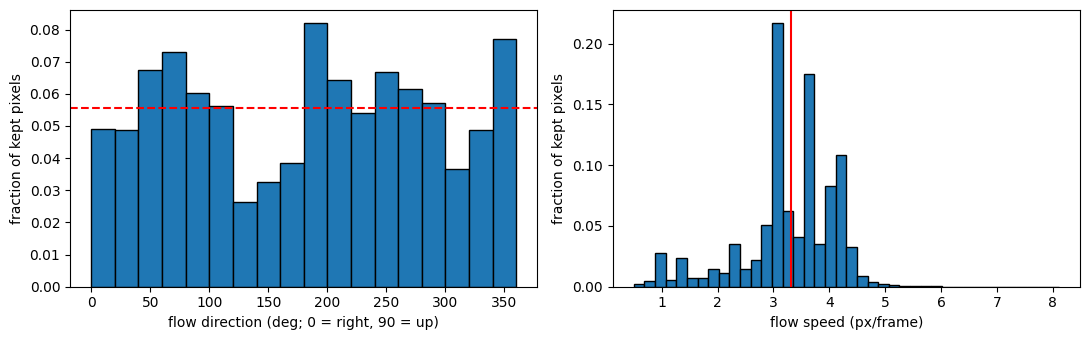

In [39]:
import cv2
thetas, speeds = [], []
for v in train_v[:50]:
    f8 = [np.ascontiguousarray(v[s, 0].numpy()) for s in range(20)]     
    for s in range(19):
        flow = cv2.calcOpticalFlowFarneback(f8[s], f8[s + 1], None, 0.5, 3, 15, 3, 5, 1.2, 0)
        dx, dy = flow[..., 0], flow[..., 1]
        mag = np.sqrt(dx ** 2 + dy ** 2)
        keep = (f8[s] > 51) & (f8[s + 1] > 51) & (mag > 0.5)           
        thetas.append(np.degrees(np.arctan2(-dy[keep], dx[keep])) % 360)
        speeds.append(mag[keep])
thetas, speeds = np.concatenate(thetas), np.concatenate(speeds)
med = np.median(speeds) if len(speeds) else float("nan")
print("pixels kept:", len(speeds), "| median speed (px/frame):", med)   

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
cnt, edges = np.histogram(thetas, bins=18, range=(0, 360))
ax[0].bar(edges[:-1], cnt / max(cnt.sum(), 1), width=20, align="edge", edgecolor="k")
ax[0].axhline(1 / 18, color="r", ls="--")
ax[0].set_xlabel("flow direction (deg; 0 = right, 90 = up)"); ax[0].set_ylabel("fraction of kept pixels")
ax[1].hist(speeds, bins=40, weights=np.ones_like(speeds) / max(len(speeds), 1), edgecolor="k")
ax[1].axvline(med, color="r"); ax[1].set_xlabel("flow speed (px/frame)"); ax[1].set_ylabel("fraction of kept pixels")
plt.tight_layout()
plt.savefig("results_fig1_optical_flow.png", dpi=200)     
plt.show()

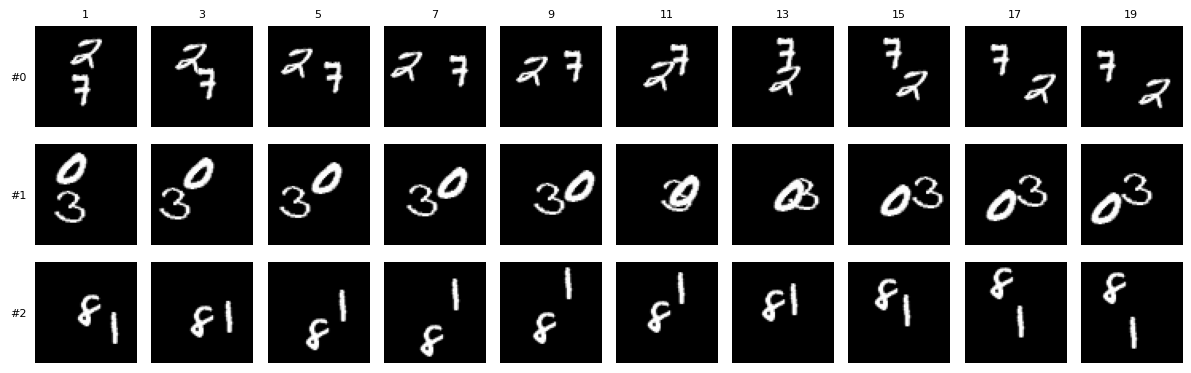

In [40]:
def show_videos(vids_u8, idxs=(0, 1, 2), frames=range(0, 20, 2)):
    frames = list(frames)
    fig, ax = plt.subplots(len(idxs), len(frames), figsize=(1.2 * len(frames), 1.3 * len(idxs)))
    ax = np.atleast_2d(ax)
    for r, i in enumerate(idxs):
        for c, f in enumerate(frames):
            ax[r, c].imshow(vids_u8[i, f, 0], cmap="gray", vmin=0, vmax=255)
            ax[r, c].axis("off")
            if r == 0: ax[r, c].set_title(f"{f + 1}", fontsize=8)
        ax[r, 0].text(-6, 32, f"#{i}", ha="right", va="center", fontsize=8)
    plt.tight_layout(); plt.show()

show_videos(train_v, idxs=(0, 1, 2))         

In [41]:
class ConvLSTMCell(nn.Module):
    def __init__(self, in_channels, hidden_channels, kernel_size=3, dilation=1):
        super().__init__()
        self.hidden_channels = hidden_channels
        padding = dilation * (kernel_size - 1) // 2
        self.gate_conv = nn.Conv2d(
            in_channels=in_channels + hidden_channels,
            out_channels=4 * hidden_channels,
            kernel_size=kernel_size,
            padding=padding,
            dilation=dilation,
            bias=True
        )

    def forward(self, input_tensor, state):
        hidden_state, cell_state = state
        combined = torch.cat([input_tensor, hidden_state], dim=1)
        gate_outputs = self.gate_conv(combined)
        input_gate, forget_gate, output_gate, candidate_gate = torch.chunk(gate_outputs, chunks=4, dim=1)
        new_cell_state = (torch.sigmoid(forget_gate) * cell_state) + (torch.sigmoid(input_gate) * torch.tanh(candidate_gate))
        new_hidden_state = torch.sigmoid(output_gate) * torch.tanh(new_cell_state)
        return new_hidden_state, new_cell_state

class ConvLSTMForecaster(nn.Module):
    def __init__(self, patch_size=4, hidden_dim=64, kernel_size=3, dilation=1, num_layers=2):
        super().__init__()
        self.patch_size, self.hidden_dim = patch_size, hidden_dim
        patch_channels = patch_size * patch_size
        self.cells = nn.ModuleList([ConvLSTMCell(patch_channels if layer_idx == 0 else hidden_dim, hidden_dim, kernel_size, dilation) for layer_idx in range(num_layers)])
        self.out_conv = nn.Conv2d(hidden_dim, patch_size * patch_size, 1, bias=True)
    def forward(self, input_frames):
        batch_size, spatial_dim = input_frames.shape[0], input_frames.shape[-1] // self.patch_size
        states = [(input_frames.new_zeros(batch_size, self.hidden_dim, spatial_dim, spatial_dim), input_frames.new_zeros(batch_size, self.hidden_dim, spatial_dim, spatial_dim)) for _ in self.cells]
        predictions, last_prediction = [], None
        for step in range(1, 10):
            current_frame = input_frames[:, step - 1] if step <= 5 else last_prediction
            patch_features = F.pixel_unshuffle(current_frame, self.patch_size)
            for layer_idx, cell in enumerate(self.cells):
                states[layer_idx] = cell(patch_features, states[layer_idx]); patch_features = states[layer_idx][0]
            last_prediction = torch.sigmoid(F.pixel_shuffle(self.out_conv(patch_features), self.patch_size))
            if step >= 5: predictions.append(last_prediction)
        return torch.stack(predictions, dim=1)

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
mA = ConvLSTMForecaster()
print("params:", count_params(mA)); assert count_params(mA) == 480_784
assert mA(torch.rand(2, 5, 1, 64, 64)).shape == (2, 5, 1, 64, 64)

params: 480784


In [42]:
class Blank(nn.Module):
    def forward(self, X): return torch.zeros_like(X)
class CopyLast(nn.Module):
    def forward(self, X): return X[:, -1:].expand(-1, 5, -1, -1, -1).clone()

def make_set(vids_u8, k=1, t=1):
    Xs, Ys, ns = zip(*[window(v.float() / 255.0, k, t) for v in vids_u8])
    return torch.stack(Xs), torch.stack(Ys), ns[0]      

@torch.no_grad()
def forecast(f, X, bs=32):
    f.to(device).eval()
    return torch.cat([f(X[i:i + bs].to(device)).cpu() for i in range(0, len(X), bs)])

def mse_h(pred, Y):      
    return ((pred - Y) ** 2).mean(dim=(2, 3, 4))

def E(mh, H=5, n_valid=5):
    return mh[:, :min(H, n_valid)].mean(1).mean().item()

def evaluate(f, X, Y, n_valid=5):
    mh = mse_h(forecast(f, X), Y)
    return dict(mse_h=mh.mean(0).tolist(), E5=E(mh, 5, n_valid), E2=E(mh, 2, n_valid))

def consistency(f, X, Y, T):     
    p, pT = forecast(f, X), forecast(f, T(X))
    C  = ((pT - T(p)) ** 2).mean(dim=(1, 2, 3, 4))
    Et = ((pT - T(Y)) ** 2).mean(dim=(1, 2, 3, 4))
    return C, Et

class Symmetrised(nn.Module):
    def __init__(self, f): super().__init__(); self.f = f
    def forward(self, X):
        return sum(g_inv(self.f(g_apply(X, g)), g) for g in G) / len(G)

@torch.no_grad()
def time_inference(f, X, bs=32):
    f.to(device).eval(); total = 0.0
    sync = (torch.cuda.synchronize if device.type == "cuda"
            else torch.mps.synchronize if device.type == "mps" else (lambda: None))
    for i in range(0, len(X), bs):
        xb = X[i:i + bs].to(device)
        sync(); t0 = time.time(); f(xb); sync()
        total += time.time() - t0
    return total
    
def fmt(x): return f"{x:.2e}" if (x != 0 and abs(x) < 1e-3) else f"{x:#.3g}"
def fmt_seeds(v0, v1): return f"{fmt((v0 + v1) / 2)} ({fmt(v0)}, {fmt(v1)})"

Xte, Yte, _ = make_set(test_v, 1, 1)
Xva, Yva, _ = make_set(val_v, 1, 1)
print("test:", Xte.shape, Yte.shape, "| val:", Xva.shape)
for nm, f in [("Blank", Blank()), ("Copy-last", CopyLast())]:
    print(nm, "C_M =", consistency(f, Xte, Yte, M)[0].mean().item(),
          "| C_R =", consistency(f, Xte, Yte, R)[0].mean().item())

test: torch.Size([1000, 5, 1, 64, 64]) torch.Size([1000, 5, 1, 64, 64]) | val: torch.Size([1000, 5, 1, 64, 64])
Blank C_M = 0.0 | C_R = 0.0
Copy-last C_M = 0.0 | C_R = 0.0


In [43]:
def sample_kt(mode):
    if mode == "normal":
        return 1, random.choice(allowed_starts(1, "normal"))
    k = random.choice([1, 2, 3])
    return k, random.choice(allowed_starts(k, "speed"))

def make_batch(vids_u8, idx, mode, sym):
    Xs, Ys, ns = [], [], []
    for i in idx:
        k, t = sample_kt(mode)
        X, Y, n = window(vids_u8[i].float() / 255.0, k, t)
        if sym:                                                   
            g = random.choice(G); X, Y = g_apply(X, g), g_apply(Y, g)
        Xs.append(X); Ys.append(Y); ns.append(n)
    return torch.stack(Xs), torch.stack(Ys), torch.tensor(ns)

def masked_loss(pred, Y, n_valid):
    se = ((pred - Y) ** 2).mean(dim=(2, 3, 4))                          
    mask = (torch.arange(5, device=se.device)[None] < n_valid[:, None].to(se.device)).float()
    return ((se * mask).sum(1) / mask.sum(1)).mean()                        
def train(make_model, vids_u8, mode="normal", sym=False, seed=0, epochs=EPOCHS, bs=32, lr=1e-3, val=None):
    set_seed(seed)                                
    model = make_model().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    times = []
    for ep in range(epochs):
        model.train(); t0 = time.time(); tot = 0.0
        perm = torch.randperm(len(vids_u8)).tolist()
        for b in range(0, len(perm), bs):
            X, Y, n = make_batch(vids_u8, perm[b:b + bs], mode, sym)
            X, Y = X.to(device), Y.to(device)
            loss = masked_loss(model(X), Y, n)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(X)
        if device.type == "cuda": torch.cuda.synchronize()
        times.append(time.time() - t0)
        msg = f"seed {seed} ep {ep+1}/{epochs} train {tot/len(perm):.5f} ({times[-1]:.1f}s)"
        if val is not None and ((ep + 1) % 5 == 0 or ep == epochs - 1):
            msg += f" | val E5 {evaluate(model, *val)['E5']:.5f}"
        print(msg)
    return model, float(np.mean(times))            

In [44]:
store = {}     
for seed in (0, 1):
    m, tt = train(lambda: ConvLSTMForecaster(), train_v, "normal", False, seed, val=(Xva, Yva))
    store[("A", seed)] = (m, tt)
    torch.save(m.state_dict(), f"ckpt_A_seed{seed}.pt")       
print("hardware:", HARDWARE)

seed 0 ep 1/30 train 0.04609 (63.5s)
seed 0 ep 2/30 train 0.03969 (62.8s)
seed 0 ep 3/30 train 0.03863 (65.8s)
seed 0 ep 4/30 train 0.03707 (63.5s)
seed 0 ep 5/30 train 0.03516 (62.8s) | val E5 0.03375
seed 0 ep 6/30 train 0.03350 (77.2s)
seed 0 ep 7/30 train 0.03217 (78.0s)
seed 0 ep 8/30 train 0.03115 (72.2s)
seed 0 ep 9/30 train 0.03048 (73.2s)
seed 0 ep 10/30 train 0.02980 (70.8s) | val E5 0.02912
seed 0 ep 11/30 train 0.02925 (76.3s)
seed 0 ep 12/30 train 0.02882 (71.5s)
seed 0 ep 13/30 train 0.02848 (72.9s)
seed 0 ep 14/30 train 0.02817 (73.5s)
seed 0 ep 15/30 train 0.02773 (74.8s) | val E5 0.02719
seed 0 ep 16/30 train 0.02738 (72.4s)
seed 0 ep 17/30 train 0.02699 (79.8s)
seed 0 ep 18/30 train 0.02656 (94.8s)
seed 0 ep 19/30 train 0.02615 (78.9s)
seed 0 ep 20/30 train 0.02576 (73.3s) | val E5 0.02539
seed 0 ep 21/30 train 0.02535 (73.1s)
seed 0 ep 22/30 train 0.02506 (71.9s)
seed 0 ep 23/30 train 0.02473 (71.1s)
seed 0 ep 24/30 train 0.02434 (72.0s)
seed 0 ep 25/30 train 0.02411

In [45]:
for name, f in [("Blank", Blank()), ("Copy-last", CopyLast())]:
    r = evaluate(f, Xte, Yte)
    print(f"{name:10s} MSE_h:", [fmt(v) for v in r["mse_h"]], "| E5:", fmt(r["E5"]), "| params: 0")
rs = [evaluate(store[("A", s)][0], Xte, Yte) for s in (0, 1)]
print("A MSE_h:", [fmt_seeds(rs[0]["mse_h"][h], rs[1]["mse_h"][h]) for h in range(5)])
print("A E5   :", fmt_seeds(rs[0]["E5"], rs[1]["E5"]), "| params:", count_params(store[("A", 0)][0]))
print("A train s/epoch:", fmt_seeds(store[("A", 0)][1], store[("A", 1)][1]),
      "| inference s (1000 test videos):",
      fmt_seeds(time_inference(store[("A", 0)][0], Xte), time_inference(store[("A", 1)][0], Xte)))

Blank      MSE_h: ['0.0426', '0.0426', '0.0426', '0.0425', '0.0425'] | E5: 0.0426 | params: 0
Copy-last  MSE_h: ['0.0492', '0.0604', '0.0669', '0.0708', '0.0732'] | E5: 0.0641 | params: 0
A MSE_h: ['0.0173 (0.0178, 0.0168)', '0.0206 (0.0212, 0.0201)', '0.0229 (0.0236, 0.0222)', '0.0247 (0.0255, 0.0239)', '0.0264 (0.0272, 0.0256)']
A E5   : 0.0224 (0.0230, 0.0217) | params: 480784
A train s/epoch: 55.4 (72.0, 38.7) | inference s (1000 test videos): 1.69 (1.72, 1.66)


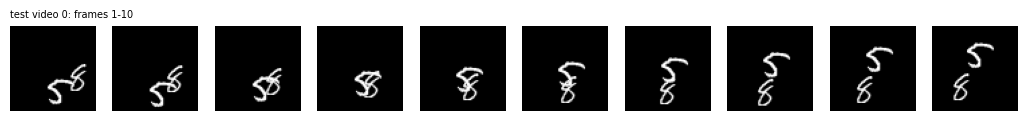

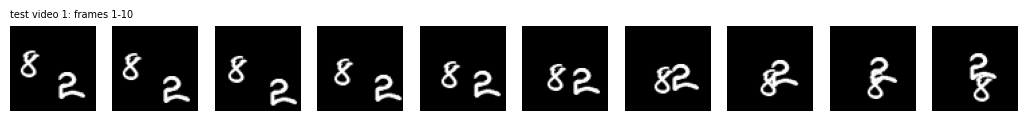

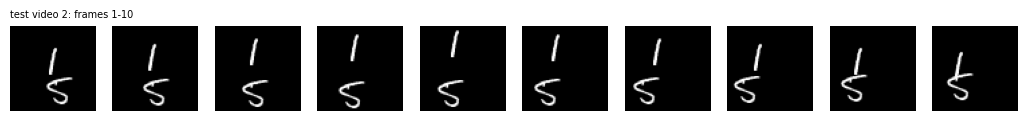

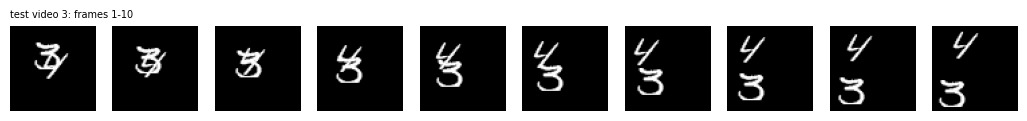

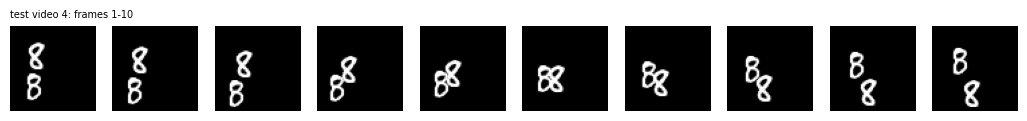

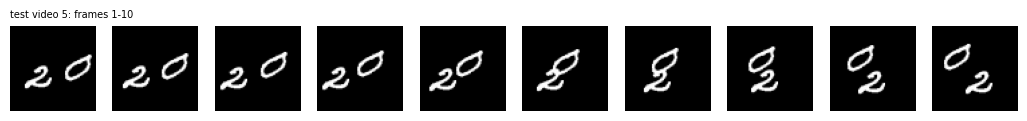

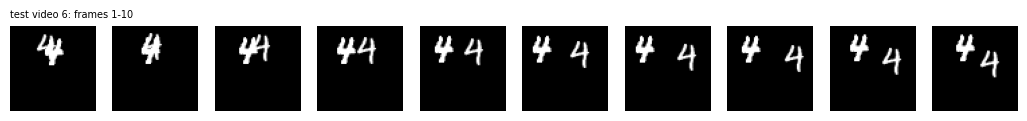

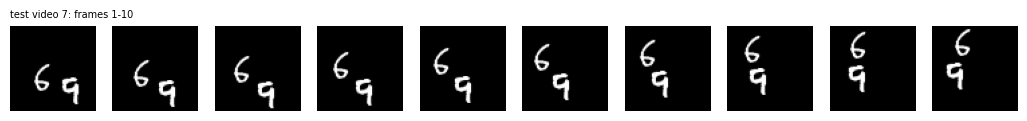

In [46]:
def show_rows(rows, row_labels, title=None, save=None):
    T = rows[0].shape[0]
    fig, ax = plt.subplots(len(rows), T, figsize=(1.3 * T, 1.3 * len(rows)))
    ax = np.atleast_2d(ax)
    for r, (row, lab) in enumerate(zip(rows, row_labels)):
        for c in range(T):
            ax[r, c].imshow(row[c, 0].cpu(), cmap="gray", vmin=0, vmax=1); ax[r, c].axis("off")
        ax[r, 0].set_title(lab, fontsize=7, loc="left")
    if title: fig.suptitle(title)
    if save: plt.savefig(save, dpi=200, bbox_inches="tight")
    plt.show()

mA0 = store[("A", 0)][0]

for i in range(8):
    show_rows([torch.cat([Xte[i], Yte[i]])], [f"test video {i}: frames 1-10"])

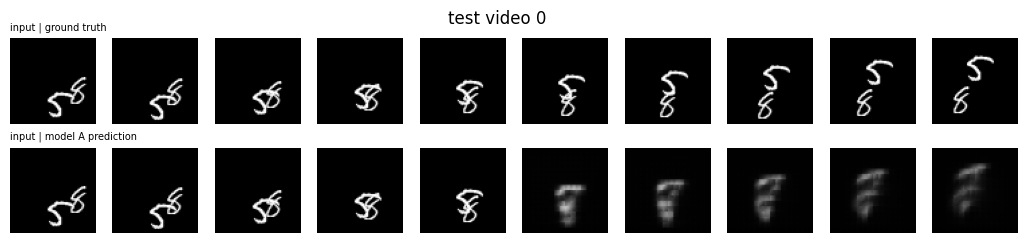

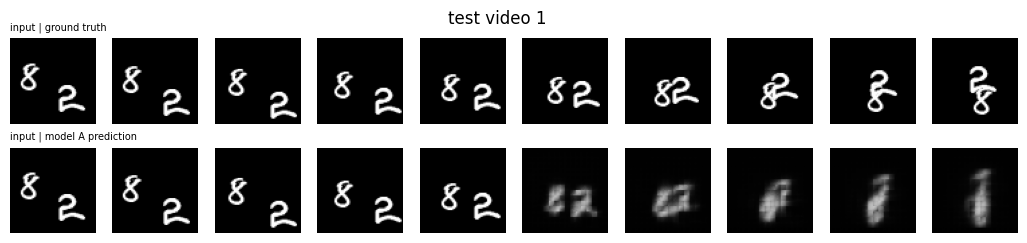

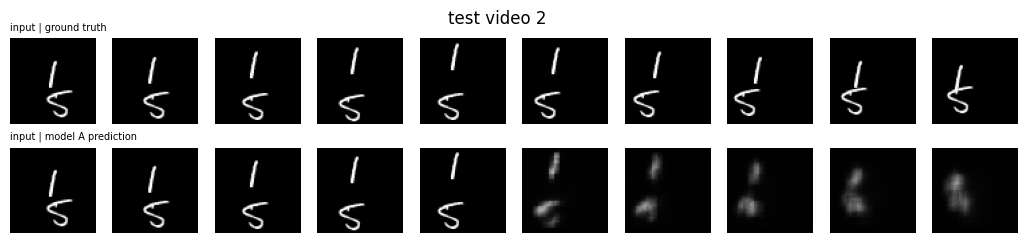

In [48]:
FIG2_IDX = [0, 1, 2]       
pA = forecast(mA0, Xte[FIG2_IDX])
for n, i in enumerate(FIG2_IDX):
    show_rows([torch.cat([Xte[i], Yte[i]]), torch.cat([Xte[i], pA[n]])],
              ["input | ground truth", "input | model A prediction"],
              title=f"test video {i}", save=f"results_fig2_video{i}.png")   # move into q2/results/

Saved successfully to: /Users/ibrahimanwar/Desktop/DL4STG_PA2 2/question2/DLSTG_PA2/q2/results/results_fig2_qualitative.png


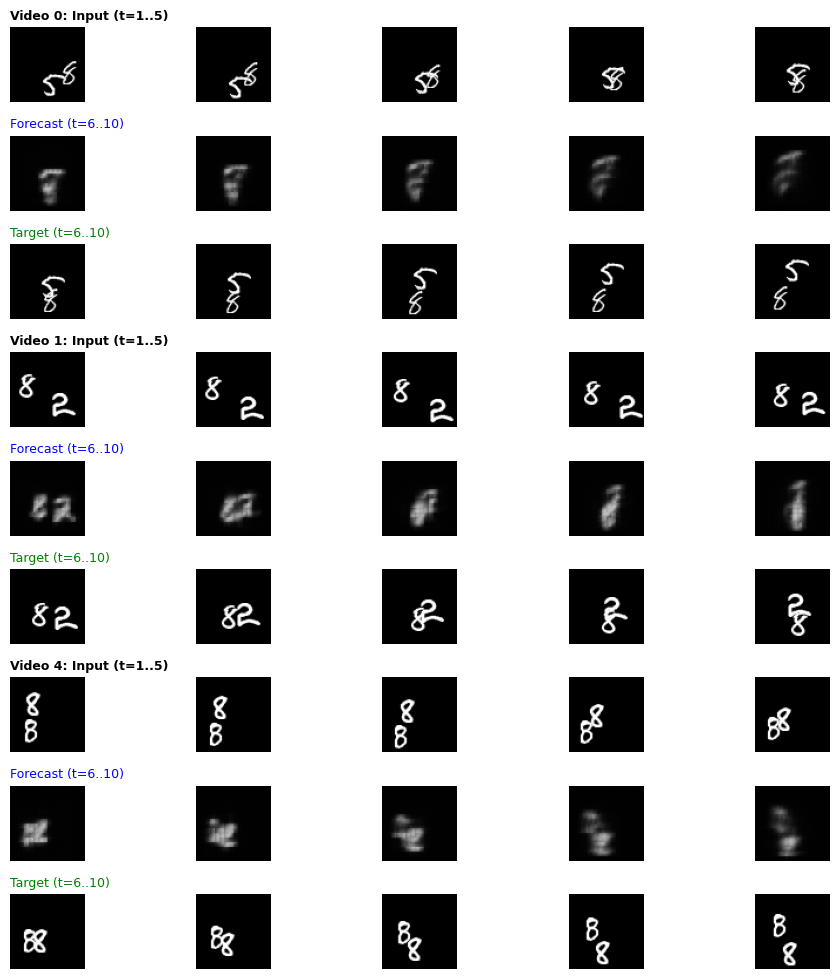

In [51]:
import matplotlib.pyplot as plt
import torch
import os

# Ensure model is in eval mode
model = store[("A", 0)][0] if ("A", 0) in store else mA
model.eval().to(device)

# Pick 3 interesting test videos (video 0, 1, and one with known overlap like video 4 or 12)
sample_indices = [0, 1, 4] 

fig, axes = plt.subplots(len(sample_indices) * 3, 5, figsize=(10, 2.2 * len(sample_indices) * 3 / 2))

with torch.no_grad():
    for row_idx, vid_idx in enumerate(sample_indices):
        X_in = Xte[vid_idx:vid_idx+1].to(device)      # shape: (1, 5, 1, 64, 64)
        Y_true = Yte[vid_idx:vid_idx+1].to(device)    # shape: (1, 5, 1, 64, 64)
        Y_pred = model(X_in).cpu()                    # shape: (1, 5, 1, 64, 64)
        X_in = X_in.cpu()
        Y_true = Y_true.cpu()
        
        base_r = row_idx * 3
        for t in range(5):
            # Row 1: Inputs (t=1..5)
            axes[base_r, t].imshow(X_in[0, t, 0], cmap="gray", vmin=0, vmax=1)
            axes[base_r, t].axis("off")
            if t == 0: axes[base_r, t].set_title(f"Video {vid_idx}: Input (t=1..5)", fontsize=9, loc="left", fontweight="bold")

            # Row 2: Model Predictions (t=6..10)
            axes[base_r + 1, t].imshow(Y_pred[0, t, 0], cmap="gray", vmin=0, vmax=1)
            axes[base_r + 1, t].axis("off")
            if t == 0: axes[base_r + 1, t].set_title("Forecast (t=6..10)", fontsize=9, loc="left", color="blue")

            # Row 3: Ground Truth (t=6..10)
            axes[base_r + 2, t].imshow(Y_true[0, t, 0], cmap="gray", vmin=0, vmax=1)
            axes[base_r + 2, t].axis("off")
            if t == 0: axes[base_r + 2, t].set_title("Target (t=6..10)", fontsize=9, loc="left", color="green")

plt.tight_layout()
out_dir = "/Users/ibrahimanwar/Desktop/DL4STG_PA2 2/question2/DLSTG_PA2/q2/results"
os.makedirs(out_dir, exist_ok=True)
save_path = os.path.join(out_dir, "results_fig2_qualitative.png")
plt.savefig(save_path, dpi=200, bbox_inches="tight")
print(f"Saved successfully to: {save_path}")
plt.show()
plt.show()